<a href="https://colab.research.google.com/github/Zsombic007/ev_battery_degradation/blob/main/Electric_vehicle_battery_degradion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EV Battery Degradation: Predicting State of Health (SoH)

## Overview
This project predicts the battery State of Health (`SoH_Percent`) of electric
vehicles from usage and vehicle data, using regression models.

In [ ]:
# import kagglehub

# # Download latest version
# path = kagglehub.dataset_download("bertnardomariouskono/electric-vehicle-ev-battery-degradation-and-charge")

# print("Path to dataset files:", path)

## Dataset
- Source: [Kaggle – EV Battery Degradation and Charge](https://www.kaggle.com/datasets/bertnardomariouskono/electric-vehicle-ev-battery-degradation-and-charge)
- 10,000 rows, 13 columns
- Target: `SoH_Percent` (range 73.74–100)
- Features: car model, battery type, capacity, vehicle age, charging cycles,
  temperature, fast charge ratio, discharge rate, driving style, internal resistance

In [ ]:
import pandas as pd

data = pd.read_csv("/content/drive/MyDrive/python_ai/ev_battery_degradation_v1.csv")
data


,Vehicle_ID,Car_Model,Battery_Type,Battery_Capacity_kWh,Vehicle_Age_Months,Total_Charging_Cycles,Avg_Temperature_C,Fast_Charge_Ratio,Avg_Discharge_Rate_C,Driving_Style,Internal_Resistance_Ohm,SoH_Percent,Battery_Status
0,1fb46ae8,Tesla Model 3,NMC,75.0,41,390,21.5,0.51,2.22,Aggressive,0.0362,94.60,Healthy
1,b7ef35aa,Tesla Model 3,NMC,75.0,29,401,18.0,0.62,1.34,Aggressive,0.0333,95.68,Healthy
2,76cb49e0,Ford Mustang Mach-E,NMC,88.0,71,941,18.4,0.78,1.48,Conservative,0.0526,89.80,Healthy
3,456a7aef,Ford Mustang Mach-E,NMC,88.0,57,378,10.8,0.61,0.72,Moderate,0.0314,96.29,Healthy
4,bd758049,Tesla Model 3,NMC,75.0,58,239,30.3,0.89,1.48,Conservative,0.0297,96.75,Healthy
...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,19f0cbd6,Tesla Model 3,NMC,75.0,91,1287,31.3,0.83,2.00,Moderate,0.0668,84.57,Healthy
9996,f157c5aa,Tesla Model 3,NMC,75.0,90,767,34.4,0.49,2.47,Moderate,0.0444,91.62,Healthy
9997,3c549739,BYD Atto 3,LFP,60.0,93,525,23.3,0.45,2.18,Moderate,0.0277,96.94,Healthy
9998,a6c88d13,Ford Mustang Mach-E,NMC,88.0,14,161,19.1,0.87,2.31,Aggressive,0.0268,97.17,Healthy


## Preprocessing
| Column | Encoding | Reason |
|---|---|---|
| `Car_Model` | One-Hot | Nominal, only 5 categories |
| `Battery_Type` | One-Hot | Nominal, 2 categories |
| `Driving_Style` | Ordinal (Conservative < Moderate < Aggressive) | Natural order |

Dropped from the features: `Vehicle_ID` (identifier) and `Battery_Status`
(derived from the target, would cause data leakage).

In [ ]:
for car in data["Car_Model"].unique():
  print(car+": "+str(len(data[data["Car_Model"] == car])))

Tesla Model 3: 2008
Ford Mustang Mach-E: 2009
Hyundai Ioniq 5: 2003
Wuling Air EV: 1948
BYD Atto 3: 2032


In [ ]:
from sklearn.preprocessing import OneHotEncoder
ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False).set_output(transform="pandas")
ohetransform = ohe.fit_transform(data[["Car_Model"]])
ohetransform

,Car_Model_BYD Atto 3,Car_Model_Ford Mustang Mach-E,Car_Model_Hyundai Ioniq 5,Car_Model_Tesla Model 3,Car_Model_Wuling Air EV
0,0.0,0.0,0.0,1.0,0.0
1,0.0,0.0,0.0,1.0,0.0
2,0.0,1.0,0.0,0.0,0.0
3,0.0,1.0,0.0,0.0,0.0
4,0.0,0.0,0.0,1.0,0.0
...,...,...,...,...,...
9995,0.0,0.0,0.0,1.0,0.0
9996,0.0,0.0,0.0,1.0,0.0
9997,1.0,0.0,0.0,0.0,0.0
9998,0.0,1.0,0.0,0.0,0.0


In [ ]:
ohe2 = OneHotEncoder(handle_unknown="ignore", sparse_output=False).set_output(transform="pandas")
ohetransform2 = ohe.fit_transform(data[["Battery_Type"]])
ohetransform2

,Battery_Type_LFP,Battery_Type_NMC
0,0.0,1.0
1,0.0,1.0
2,0.0,1.0
3,0.0,1.0
4,0.0,1.0
...,...,...
9995,0.0,1.0
9996,0.0,1.0
9997,1.0,0.0
9998,0.0,1.0


In [ ]:
from sklearn.preprocessing import OrdinalEncoder
driving_styles = list(data["Driving_Style"].unique())
enc = OrdinalEncoder(categories=[["Conservative", "Moderate", "Aggressive"]]).set_output(transform="pandas")
ordinalenctransorm = enc.fit_transform(data[["Driving_Style"]])



Driving Style
Aggressive 0.0
Conservative 1.0
Moderate 2.0

In [ ]:
data = pd.concat([data, ohetransform], axis=1).drop("Car_Model", axis=1)
data = pd.concat([data, ohetransform2], axis=1).drop("Battery_Type", axis=1)
data["Driving_Style"] = ordinalenctransorm
data

,Vehicle_ID,Battery_Capacity_kWh,Vehicle_Age_Months,Total_Charging_Cycles,Avg_Temperature_C,Fast_Charge_Ratio,Avg_Discharge_Rate_C,Driving_Style,Internal_Resistance_Ohm,SoH_Percent,Battery_Status,Car_Model_BYD Atto 3,Car_Model_Ford Mustang Mach-E,Car_Model_Hyundai Ioniq 5,Car_Model_Tesla Model 3,Car_Model_Wuling Air EV,Battery_Type_LFP,Battery_Type_NMC
0,1fb46ae8,75.0,41,390,21.5,0.51,2.22,2.0,0.0362,94.60,Healthy,0.0,0.0,0.0,1.0,0.0,0.0,1.0
1,b7ef35aa,75.0,29,401,18.0,0.62,1.34,2.0,0.0333,95.68,Healthy,0.0,0.0,0.0,1.0,0.0,0.0,1.0
2,76cb49e0,88.0,71,941,18.4,0.78,1.48,0.0,0.0526,89.80,Healthy,0.0,1.0,0.0,0.0,0.0,0.0,1.0
3,456a7aef,88.0,57,378,10.8,0.61,0.72,1.0,0.0314,96.29,Healthy,0.0,1.0,0.0,0.0,0.0,0.0,1.0
4,bd758049,75.0,58,239,30.3,0.89,1.48,0.0,0.0297,96.75,Healthy,0.0,0.0,0.0,1.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,19f0cbd6,75.0,91,1287,31.3,0.83,2.00,1.0,0.0668,84.57,Healthy,0.0,0.0,0.0,1.0,0.0,0.0,1.0
9996,f157c5aa,75.0,90,767,34.4,0.49,2.47,1.0,0.0444,91.62,Healthy,0.0,0.0,0.0,1.0,0.0,0.0,1.0
9997,3c549739,60.0,93,525,23.3,0.45,2.18,1.0,0.0277,96.94,Healthy,1.0,0.0,0.0,0.0,0.0,1.0,0.0
9998,a6c88d13,88.0,14,161,19.1,0.87,2.31,2.0,0.0268,97.17,Healthy,0.0,1.0,0.0,0.0,0.0,0.0,1.0


In [ ]:
for car in data["Battery_Status"].unique():
  print(car+": "+str(len(data[data["Battery_Status"] == car])))

Healthy: 9996
Replace Required: 4


## Why no classification model?
`Battery_Status` is extremely imbalanced (9,996 "Healthy" vs. 4 "Replace Required").
A model that always predicts "Healthy" would reach 99.96% accuracy while being useless.
In addition, the status is a threshold on `SoH_Percent` (~80%), so a classifier would
only learn that threshold. Oversampling (e.g. SMOTE) cannot create real patterns from 4 samples.


In [ ]:
print(data.groupby("Battery_Status")["SoH_Percent"].agg(["min", "max"]))

                    min     max
Battery_Status                 
Healthy           80.17  100.00
Replace Required  73.74   78.96


In [ ]:
X = data.drop(columns = ["SoH_Percent","Vehicle_ID", "Battery_Status"])
y = data["SoH_Percent"]

In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## Models
Train/test split: 80/20, `random_state=42`.

| Model | RMSE (test) | R² (test) |
|---|---|---|
| Linear Regression | 0.4132 | 0.9839 |
| Random Forest Regressor | 0.3770 | 0.9866 |

In [ ]:
from sklearn.linear_model import LinearRegression
reg = LinearRegression().fit(X_train,y_train)

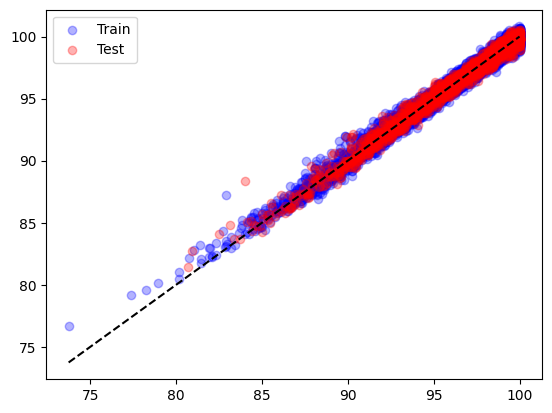

In [ ]:
import matplotlib.pyplot as plt

y_pred = reg.predict(X_test)

plt.scatter(y_train, reg.predict(X_train), color="blue", alpha=0.3, label="Train")
plt.scatter(y_test, reg.predict(X_test), color="red", alpha=0.3, label="Test")
plt.plot([y.min(), y.max()], [y.min(), y.max()], "k--")
plt.legend()
plt.show()

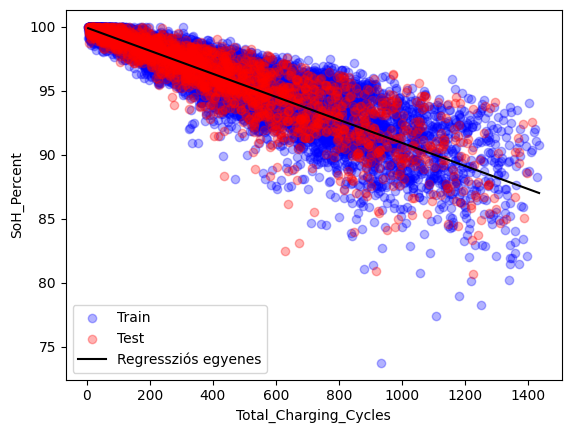

In [ ]:
import numpy as np
col = ["Total_Charging_Cycles"]
model1 = LinearRegression().fit(X_train[col], y_train)

plt.scatter(X_train[col], y_train, color="blue", alpha=0.3, label="Train")
plt.scatter(X_test[col], y_test, color="red", alpha=0.3, label="Test")

xs = np.linspace(X[col].min(), X[col].max(), 100)
plt.plot(xs, model1.predict(pd.DataFrame(xs, columns=col)), color="black", label="Regressziós egyenes")

plt.xlabel(col[0])
plt.ylabel("SoH_Percent")
plt.legend()
plt.show()

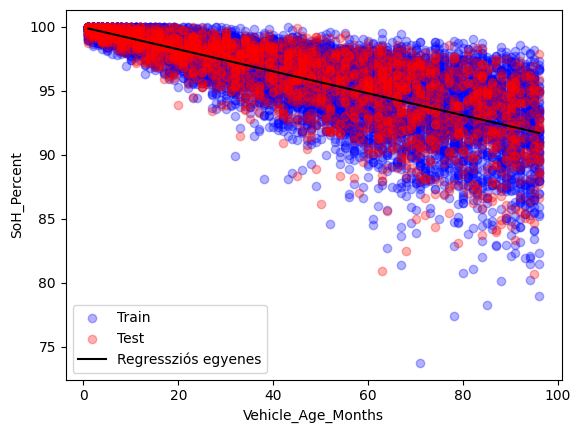

In [ ]:
col = ["Vehicle_Age_Months"]
model2 = LinearRegression().fit(X_train[col], y_train)

plt.scatter(X_train[col], y_train, color="blue", alpha=0.3, label="Train")
plt.scatter(X_test[col], y_test, color="red", alpha=0.3, label="Test")

xs = np.linspace(X[col].min(), X[col].max(), 100)
plt.plot(xs, model2.predict(pd.DataFrame(xs, columns=col)), color="black", label="Regressziós egyenes")

plt.xlabel(col[0])
plt.ylabel("SoH_Percent")
plt.legend()
plt.show()

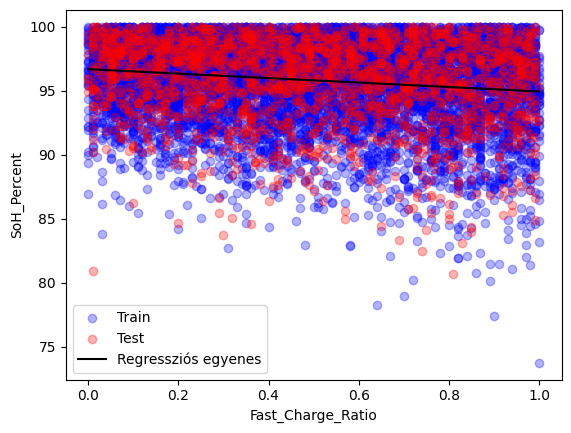

In [ ]:


col = ["Fast_Charge_Ratio"]
model3 = LinearRegression().fit(X_train[col], y_train)

plt.scatter(X_train[col], y_train, color="blue", alpha=0.3, label="Train")
plt.scatter(X_test[col], y_test, color="red", alpha=0.3, label="Test")

xs = np.linspace(X[col].min(), X[col].max(), 100)
plt.plot(xs, model3.predict(pd.DataFrame(xs, columns=col)), color="black", label="Regressziós egyenes")

plt.xlabel(col[0])
plt.ylabel("SoH_Percent")
plt.legend()
plt.show()

In [ ]:
from sklearn.metrics import root_mean_squared_error
print(f"R²= {reg.score(X_test, y_test)}")
RMSE = root_mean_squared_error(y_test, reg.predict(X_test))
print(f"RMSE: {RMSE}")

R²= 0.9839422285617089
RMSE: 0.413202018236692


In [ ]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(random_state=42).fit(X_train, y_train)
print(f"R²= {rf.score(X_test, y_test)}")
print(f"RMSE: {root_mean_squared_error(y_test, rf.predict(X_test))}")

R²= 0.986631323548558
RMSE: 0.3770196660653116


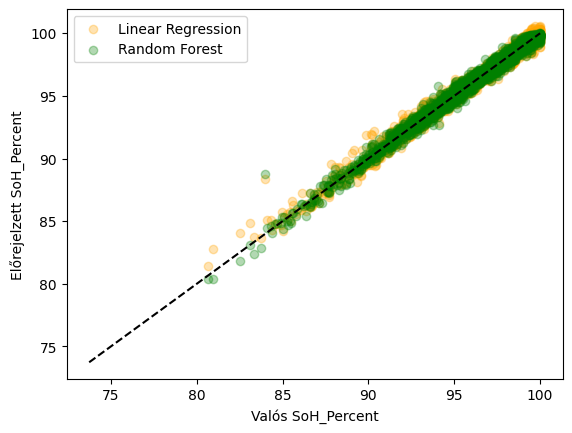

In [ ]:
plt.scatter(y_test, reg.predict(X_test), color="orange", alpha=0.3, label="Linear Regression")
plt.scatter(y_test, rf.predict(X_test), color="green", alpha=0.3, label="Random Forest")
plt.plot([y.min(), y.max()], [y.min(), y.max()], "k--")
plt.xlabel("Valós SoH_Percent")
plt.ylabel("Előrejelzett SoH_Percent")
plt.legend()
plt.show()

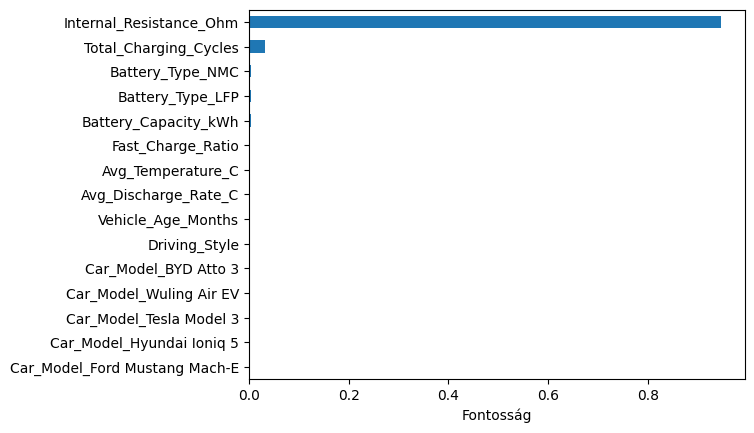

In [ ]:
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
imp.plot(kind="barh")
plt.xlabel("Fontosság")
plt.show()

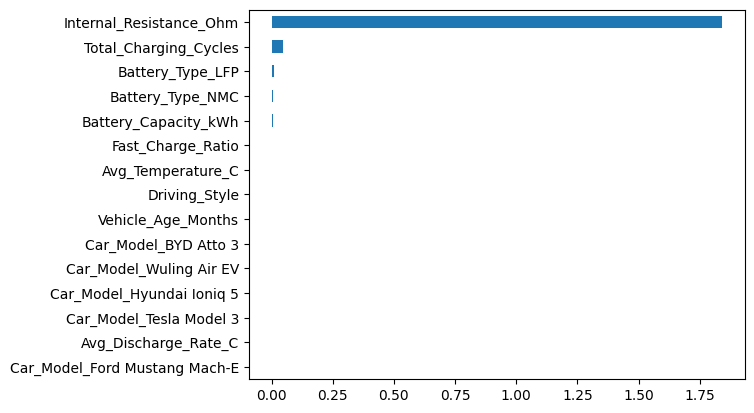

In [ ]:
from sklearn.inspection import permutation_importance

r = permutation_importance(rf, X_test, y_test, n_repeats=10, random_state=42)
pd.Series(r.importances_mean, index=X.columns).sort_values().plot(kind="barh")
plt.show()

## Results and limitations
- The Random Forest Regressorn performed slightly better
- Most important features: `Internal_Resistance_Ohm` dominates the Random Forest
  (95% of the impurity-based importance, confirmed by permutation importance on
  the test set), followed by `Total_Charging_Cycles` (3%). All other features,
  including car model, driving style and vehicle age, contribute almost nothing.
  Note that internal resistance is itself a direct physical indicator of battery
  degradation, so it acts as a proxy for SoH rather than an independent cause.
- The dataset appears to be synthetic
  results may not transfer to real-world data.


## How to run
```bash
pip install pandas scikit-learn matplotlib
```
Open the notebook in Google Colab and run all cells.